# Assignment 3



In [2]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from mlxtend.frequent_patterns import apriori, association_rules

sns.set_theme(style='whitegrid')

In [3]:
# Load the student performance dataset
df1 = pd.read_csv('Student_Performance.csv')
print('Dataset shape:', df1.shape)
print('First 5 rows:')
display(df1.head())

Dataset shape: (10000, 6)
First 5 rows:


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [4]:
# 1. Perform exploratory data analysis and identify the variables
print('Number of rows:', df1.shape[0])
print('Number of columns:', df1.shape[1])
print('Column names:', df1.columns.tolist())
df1.info()

Number of rows: 10000
Number of columns: 6
Column names: ['Hours Studied', 'Previous Scores', 'Extracurricular Activities', 'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index']
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  str    
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), str(1)
memory usage: 468.9 KB


In [5]:
# Check missing values and duplicate rows
print('Missing values in each column:')
print(df1.isnull().sum())
print('Duplicate rows:', df1.duplicated().sum())

# Duplicate rows are counted here but are not removed automatically.

Missing values in each column:
Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64
Duplicate rows: 127


In [6]:
# Summary statistics
print(df1.describe())
print(df1.describe(include='object'))

       Hours Studied  Previous Scores   Sleep Hours  \
count   10000.000000     10000.000000  10000.000000   
mean        4.992900        69.445700      6.530600   
std         2.589309        17.343152      1.695863   
min         1.000000        40.000000      4.000000   
25%         3.000000        54.000000      5.000000   
50%         5.000000        69.000000      7.000000   
75%         7.000000        85.000000      8.000000   
max         9.000000        99.000000      9.000000   

       Sample Question Papers Practiced  Performance Index  
count                      10000.000000       10000.000000  
mean                           4.583300          55.224800  
std                            2.867348          19.212558  
min                            0.000000          10.000000  
25%                            2.000000          40.000000  
50%                            5.000000          55.000000  
75%                            7.000000          71.000000  
max             

C:\Users\Ashu\AppData\Local\Temp\ipykernel_14992\3220013591.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df1.describe(include='object'))


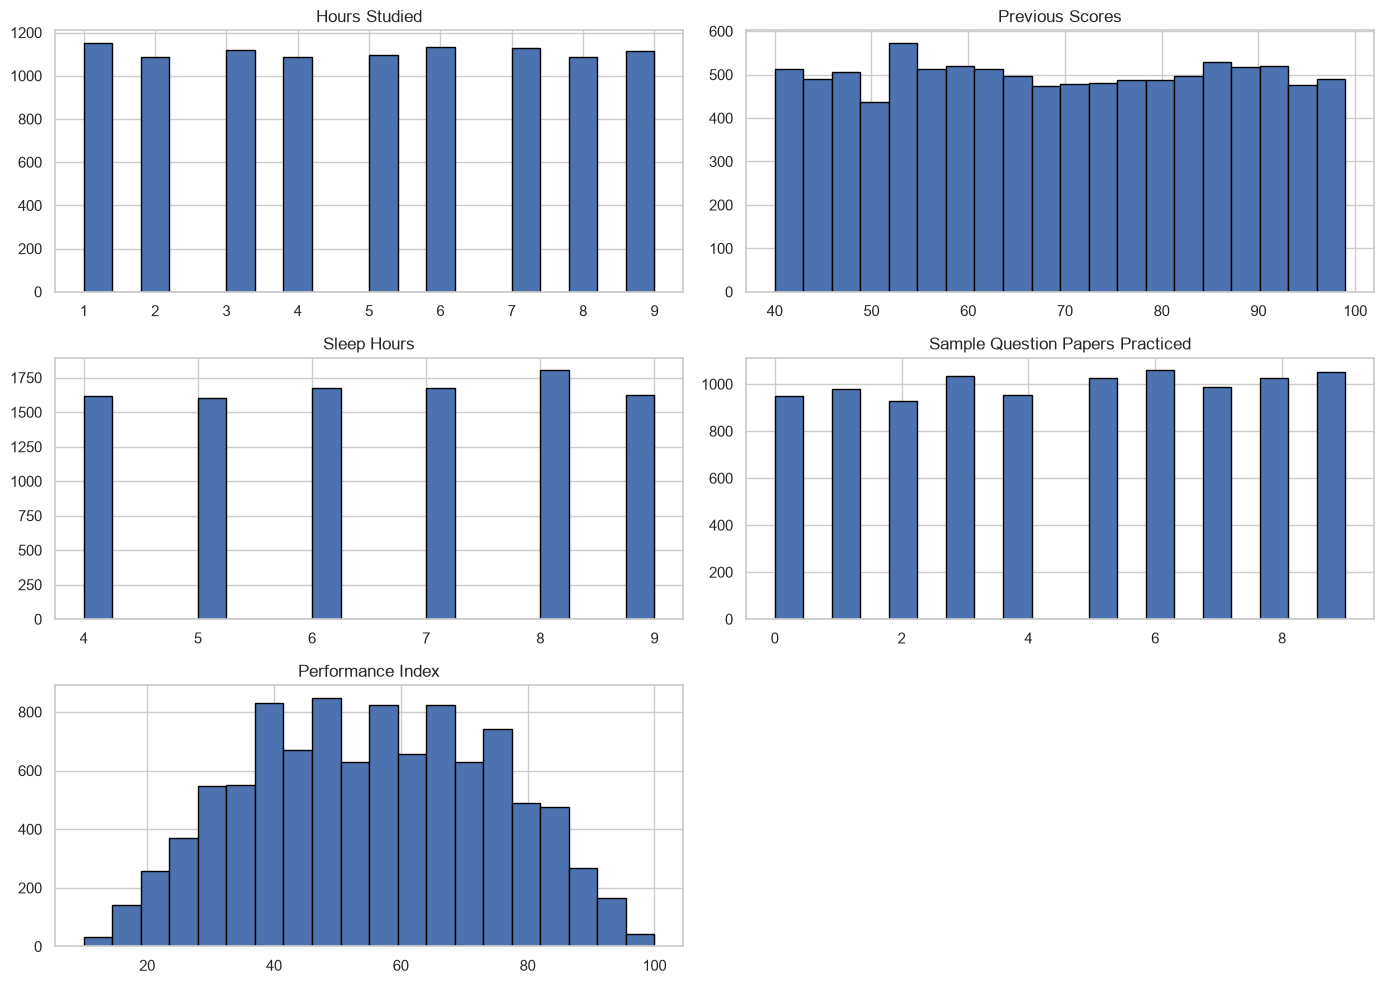

In [7]:
# Plot the numerical feature distributions
df1.hist(figsize=(14, 10), bins=20, edgecolor='black')
plt.tight_layout()
plt.show()

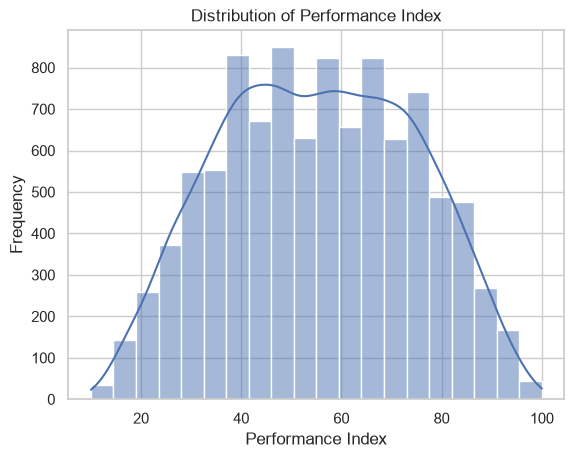

In [8]:
# Plot the distribution of the performance index
sns.histplot(data=df1, x='Performance Index', bins=20, kde=True)
plt.title('Distribution of Performance Index')
plt.xlabel('Performance Index')
plt.ylabel('Frequency')
plt.show()

C:\Users\Ashu\AppData\Local\Temp\ipykernel_14992\33313119.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols_eda = df1.select_dtypes(include=['object', 'category']).columns.tolist()


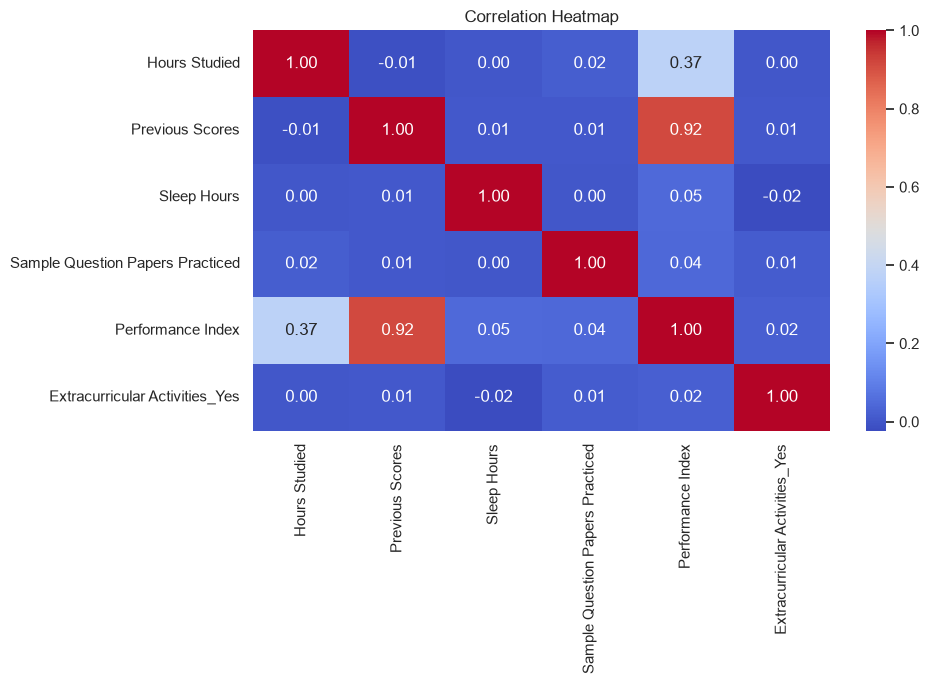

In [9]:
# Correlation heatmap
cat_cols_eda = df1.select_dtypes(include=['object', 'category']).columns.tolist()
df1_encoded = pd.get_dummies(df1, columns=cat_cols_eda, drop_first=True, dtype=int)

plt.figure(figsize=(10, 7))
sns.heatmap(df1_encoded.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [10]:
# Identify independent and dependent variables
X = df1.drop(columns=['Performance Index'])
y = df1['Performance Index']

print('Independent variables:', X.columns.tolist())
print('Dependent variable:', y.name)

Independent variables: ['Hours Studied', 'Previous Scores', 'Extracurricular Activities', 'Sleep Hours', 'Sample Question Papers Practiced']
Dependent variable: Performance Index


In [11]:
# Prepare the data for regression models
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_preprocessor, numeric_cols),
    ('cat', categorical_preprocessor, categorical_cols)
])

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

if hasattr(X_train, 'toarray'):
    X_train = X_train.toarray()
if hasattr(X_test, 'toarray'):
    X_test = X_test.toarray()

feature_names = preprocessor.get_feature_names_out()
print('Training samples:', X_train.shape[0])
print('Testing samples:', X_test.shape[0])
print('Features after encoding:', list(feature_names))

Training samples: 8000
Testing samples: 2000
Features after encoding: ['num__Hours Studied', 'num__Previous Scores', 'num__Sleep Hours', 'num__Sample Question Papers Practiced', 'cat__Extracurricular Activities_Yes']


In [12]:
# 2. Build a Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)
print('Linear Regression model trained.')

Linear Regression model trained.


In [13]:
# Evaluate Linear Regression
print('MAE:', mean_absolute_error(y_test, y_pred_linear))
print('MSE:', mean_squared_error(y_test, y_pred_linear))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred_linear)))
print('R2:', r2_score(y_test, y_pred_linear))

MAE: 1.6111213463123049
MSE: 4.082628398521858
RMSE: 2.0205515085050068
R2: 0.9889832909573145


In [14]:
# Show actual and predicted performance scores
linear_predictions = pd.DataFrame({
    'Actual Performance Index': y_test.to_numpy(),
    'Predicted Performance Index': y_pred_linear
})
print(linear_predictions.head(10).round(2))

   Actual Performance Index  Predicted Performance Index
0                      51.0                        54.71
1                      20.0                        22.62
2                      46.0                        47.90
3                      28.0                        31.29
4                      41.0                        43.00
5                      59.0                        59.07
6                      48.0                        45.90
7                      87.0                        86.46
8                      37.0                        37.70
9                      73.0                        72.06


In [15]:
# Display Linear Regression coefficients
linear_coefficients = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': linear_model.coef_
}).sort_values('Coefficient', key=abs, ascending=False)
print(linear_coefficients)

# A positive coefficient increases the predicted score when other features are held constant.

                                 Feature  Coefficient
0                     num__Hours Studied     2.852484
1                   num__Previous Scores     1.016988
4    cat__Extracurricular Activities_Yes     0.608617
2                       num__Sleep Hours     0.476941
3  num__Sample Question Papers Practiced     0.191831


In [16]:
# 3. Polynomial Regression with degree 2
poly2 = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly2 = poly2.fit_transform(X_train)
X_test_poly2 = poly2.transform(X_test)

poly_model_2 = LinearRegression()
poly_model_2.fit(X_train_poly2, y_train)
y_pred_poly2 = poly_model_2.predict(X_test_poly2)

print('Degree 2 Polynomial Regression')
print('MAE:', mean_absolute_error(y_test, y_pred_poly2))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred_poly2)))
print('R2:', r2_score(y_test, y_pred_poly2))

Degree 2 Polynomial Regression
MAE: 1.6115229438314658
RMSE: 2.020060173893702
R2: 0.988988648140549


In [17]:
# Polynomial Regression with degree 3
poly3 = PolynomialFeatures(degree=3, include_bias=False)
X_train_poly3 = poly3.fit_transform(X_train)
X_test_poly3 = poly3.transform(X_test)

poly_model_3 = LinearRegression()
poly_model_3.fit(X_train_poly3, y_train)
y_pred_poly3 = poly_model_3.predict(X_test_poly3)

print('Degree 3 Polynomial Regression')
print('MAE:', mean_absolute_error(y_test, y_pred_poly3))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred_poly3)))
print('R2:', r2_score(y_test, y_pred_poly3))

Degree 3 Polynomial Regression
MAE: 1.631284329332
RMSE: 2.0408039715822897
R2: 0.9887613380284112


In [18]:
# Compare Linear and Polynomial Regression results
regression_comparison = pd.DataFrame([
    ['Linear Regression', mean_absolute_error(y_test, y_pred_linear), mean_squared_error(y_test, y_pred_linear), np.sqrt(mean_squared_error(y_test, y_pred_linear)), r2_score(y_test, y_pred_linear)],
    ['Polynomial Regression (degree 2)', mean_absolute_error(y_test, y_pred_poly2), mean_squared_error(y_test, y_pred_poly2), np.sqrt(mean_squared_error(y_test, y_pred_poly2)), r2_score(y_test, y_pred_poly2)],
    ['Polynomial Regression (degree 3)', mean_absolute_error(y_test, y_pred_poly3), mean_squared_error(y_test, y_pred_poly3), np.sqrt(mean_squared_error(y_test, y_pred_poly3)), r2_score(y_test, y_pred_poly3)]
], columns=['Model', 'MAE', 'MSE', 'RMSE', 'R2'])

print(regression_comparison.round(4))

# Lower error and higher R2 indicate better test-set performance.

                              Model     MAE     MSE    RMSE      R2
0                 Linear Regression  1.6111  4.0826  2.0206  0.9890
1  Polynomial Regression (degree 2)  1.6115  4.0806  2.0201  0.9890
2  Polynomial Regression (degree 3)  1.6313  4.1649  2.0408  0.9888


In [19]:
# 4. Convert the performance score into pass/fail classes
# The assignment does not specify a threshold, so 50 is used as an example.
pass_mark = 50
y_class = (df1['Performance Index'] >= pass_mark).astype(int)
print(y_class.value_counts().rename(index={0: 'Fail', 1: 'Pass'}))

Performance Index
Pass    5909
Fail    4091
Name: count, dtype: int64


In [20]:
# Split and preprocess data for Logistic Regression
Xc_train_raw, Xc_test_raw, yc_train, yc_test = train_test_split(
    X, y_class, test_size=0.2, random_state=42, stratify=y_class
)

classification_preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numeric_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
    ]), categorical_cols)
])

Xc_train = classification_preprocessor.fit_transform(Xc_train_raw)
Xc_test = classification_preprocessor.transform(Xc_test_raw)

In [21]:
# Train Logistic Regression
logistic_model = LogisticRegression(max_iter=2000, random_state=42)
logistic_model.fit(Xc_train, yc_train)
y_pred_logistic = logistic_model.predict(Xc_test)
print('Logistic Regression model trained.')

Logistic Regression model trained.


In [22]:
# Evaluate Logistic Regression using classification metrics
print('Accuracy:', accuracy_score(yc_test, y_pred_logistic))
print('Precision:', precision_score(yc_test, y_pred_logistic, zero_division=0))
print('Recall:', recall_score(yc_test, y_pred_logistic, zero_division=0))
print('F1-score:', f1_score(yc_test, y_pred_logistic, zero_division=0))
print(classification_report(yc_test, y_pred_logistic, target_names=['Fail', 'Pass'], zero_division=0))

Accuracy: 0.9765
Precision: 0.9756915339480302
Recall: 0.9847715736040609
F1-score: 0.9802105263157894
              precision    recall  f1-score   support

        Fail       0.98      0.96      0.97       818
        Pass       0.98      0.98      0.98      1182

    accuracy                           0.98      2000
   macro avg       0.98      0.97      0.98      2000
weighted avg       0.98      0.98      0.98      2000



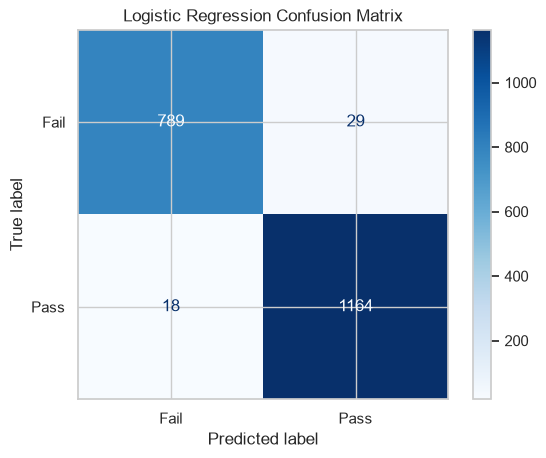

In [23]:
# Confusion matrix for Logistic Regression
cm = confusion_matrix(yc_test, y_pred_logistic)
ConfusionMatrixDisplay(cm, display_labels=['Fail', 'Pass']).plot(cmap='Blues')
plt.title('Logistic Regression Confusion Matrix')
plt.show()

# The threshold used here is 50; use the pass mark given by your instructor if different.

In [24]:
# 5. Stepwise Regression using forward feature selection
stepwise_selector = SequentialFeatureSelector(
    LinearRegression(),
    n_features_to_select='auto',
    direction='forward',
    scoring='r2',
    cv=5,
    n_jobs=-1
)
stepwise_selector.fit(X_train, y_train)
selected_mask = stepwise_selector.get_support()
selected_features = np.asarray(feature_names)[selected_mask]

print('Features in full model:', list(feature_names))
print('Features selected by stepwise regression:', selected_features.tolist())

Features in full model: ['num__Hours Studied', 'num__Previous Scores', 'num__Sleep Hours', 'num__Sample Question Papers Practiced', 'cat__Extracurricular Activities_Yes']
Features selected by stepwise regression: ['num__Hours Studied', 'num__Previous Scores']


In [25]:
# Train and evaluate Stepwise Regression
X_train_stepwise = X_train[:, selected_mask]
X_test_stepwise = X_test[:, selected_mask]

stepwise_model = LinearRegression()
stepwise_model.fit(X_train_stepwise, y_train)
y_pred_stepwise = stepwise_model.predict(X_test_stepwise)

print('Full model R2:', r2_score(y_test, y_pred_linear))
print('Stepwise model R2:', r2_score(y_test, y_pred_stepwise))
print('Full model RMSE:', np.sqrt(mean_squared_error(y_test, y_pred_linear)))
print('Stepwise model RMSE:', np.sqrt(mean_squared_error(y_test, y_pred_stepwise)))

Full model R2: 0.9889832909573145
Stepwise model R2: 0.985855014245765
Full model RMSE: 2.0205515085050068
Stepwise model RMSE: 2.2895242271160865


In [26]:
# Compare full-model and stepwise-model coefficients
stepwise_coefficients = pd.DataFrame({
    'Feature': selected_features,
    'Stepwise Coefficient': stepwise_model.coef_
})
print('Full model coefficients:')
print(linear_coefficients)
print('Stepwise coefficients:')
print(stepwise_coefficients)

# Stepwise selection may keep fewer predictors, but correlated features can affect which ones are selected.

Full model coefficients:
                                 Feature  Coefficient
0                     num__Hours Studied     2.852484
1                   num__Previous Scores     1.016988
4    cat__Extracurricular Activities_Yes     0.608617
2                       num__Sleep Hours     0.476941
3  num__Sample Question Papers Practiced     0.191831
Stepwise coefficients:
                Feature  Stepwise Coefficient
0    num__Hours Studied              2.858155
1  num__Previous Scores              1.017372


In [27]:
# 6. Evaluate all regression models using MAE, MSE, RMSE and R2
all_regression_results = pd.DataFrame([
    ['Linear Regression', mean_absolute_error(y_test, y_pred_linear), mean_squared_error(y_test, y_pred_linear), np.sqrt(mean_squared_error(y_test, y_pred_linear)), r2_score(y_test, y_pred_linear)],
    ['Polynomial Regression (degree 2)', mean_absolute_error(y_test, y_pred_poly2), mean_squared_error(y_test, y_pred_poly2), np.sqrt(mean_squared_error(y_test, y_pred_poly2)), r2_score(y_test, y_pred_poly2)],
    ['Polynomial Regression (degree 3)', mean_absolute_error(y_test, y_pred_poly3), mean_squared_error(y_test, y_pred_poly3), np.sqrt(mean_squared_error(y_test, y_pred_poly3)), r2_score(y_test, y_pred_poly3)],
    ['Stepwise Regression', mean_absolute_error(y_test, y_pred_stepwise), mean_squared_error(y_test, y_pred_stepwise), np.sqrt(mean_squared_error(y_test, y_pred_stepwise)), r2_score(y_test, y_pred_stepwise)]
], columns=['Model', 'MAE', 'MSE', 'RMSE', 'R2'])

print(all_regression_results.sort_values('RMSE').round(4))

                              Model     MAE     MSE    RMSE      R2
1  Polynomial Regression (degree 2)  1.6115  4.0806  2.0201  0.9890
0                 Linear Regression  1.6111  4.0826  2.0206  0.9890
2  Polynomial Regression (degree 3)  1.6313  4.1649  2.0408  0.9888
3               Stepwise Regression  1.8269  5.2419  2.2895  0.9859


In [28]:
# 7. Standardize the features for Ridge and Lasso
regularization_scaler = StandardScaler()
X_train_scaled = regularization_scaler.fit_transform(X_train)
X_test_scaled = regularization_scaler.transform(X_test)

linear_scaled_model = LinearRegression()
linear_scaled_model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 7.4 ,17.64, 0.81, 0.55, 0.3 ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,55.31
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](5,)","[90.41,90.06,89.86,88.69,88.17]"


In [29]:
# Apply Ridge and Lasso regularization
ridge_model = Ridge(alpha=1.0)
lasso_model = Lasso(alpha=0.1, max_iter=20000)

ridge_model.fit(X_train_scaled, y_train)
lasso_model.fit(X_train_scaled, y_train)

y_pred_ridge = ridge_model.predict(X_test_scaled)
y_pred_lasso = lasso_model.predict(X_test_scaled)
print('Ridge and Lasso models trained.')

Ridge and Lasso models trained.


In [30]:
# Compare Linear, Ridge and Lasso performance
regularization_results = pd.DataFrame([
    ['Linear Regression (scaled)', mean_absolute_error(y_test, linear_scaled_model.predict(X_test_scaled)), np.sqrt(mean_squared_error(y_test, linear_scaled_model.predict(X_test_scaled))), r2_score(y_test, linear_scaled_model.predict(X_test_scaled))],
    ['Ridge Regression', mean_absolute_error(y_test, y_pred_ridge), np.sqrt(mean_squared_error(y_test, y_pred_ridge)), r2_score(y_test, y_pred_ridge)],
    ['Lasso Regression', mean_absolute_error(y_test, y_pred_lasso), np.sqrt(mean_squared_error(y_test, y_pred_lasso)), r2_score(y_test, y_pred_lasso)]
], columns=['Model', 'MAE', 'RMSE', 'R2'])
print(regularization_results.round(4))

                        Model     MAE    RMSE      R2
0  Linear Regression (scaled)  1.6111  2.0206  0.9890
1            Ridge Regression  1.6112  2.0207  0.9890
2            Lasso Regression  1.6267  2.0434  0.9887


In [31]:
# Compare model coefficients
coefficient_comparison = pd.DataFrame({
    'Feature': feature_names,
    'Linear': linear_scaled_model.coef_,
    'Ridge': ridge_model.coef_,
    'Lasso': lasso_model.coef_
})
print(coefficient_comparison.round(4))
print('Non-zero Lasso coefficients:', np.count_nonzero(np.abs(lasso_model.coef_) > 1e-8))

# Ridge shrinks coefficients; Lasso can shrink some coefficients to exactly zero.

                                 Feature   Linear    Ridge    Lasso
0                     num__Hours Studied   7.4013   7.4004   7.3027
1                   num__Previous Scores  17.6373  17.6351  17.5375
2                       num__Sleep Hours   0.8100   0.8099   0.7087
3  num__Sample Question Papers Practiced   0.5488   0.5488   0.4512
4    cat__Extracurricular Activities_Yes   0.3043   0.3043   0.2027
Non-zero Lasso coefficients: 5


In [32]:
# 8. Prepare and standardize numerical features for PCA
pca_numeric_cols = df1.drop(columns=['Performance Index']).select_dtypes(include=np.number).columns.tolist()
X_pca_data = df1[pca_numeric_cols].copy()
X_pca_data = X_pca_data.fillna(X_pca_data.median())

pca_scaler = StandardScaler()
X_pca_scaled = pca_scaler.fit_transform(X_pca_data)
print('Features used for PCA:', pca_numeric_cols)

Features used for PCA: ['Hours Studied', 'Previous Scores', 'Sleep Hours', 'Sample Question Papers Practiced']


In [33]:
# Apply PCA to reduce the data to two principal components
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_pca_scaled)

print('Explained variance ratio:', pca.explained_variance_ratio_)
print('Total variance explained by two components:', pca.explained_variance_ratio_.sum())

Explained variance ratio: [0.25463279 0.25282751]
Total variance explained by two components: 0.507460304651535


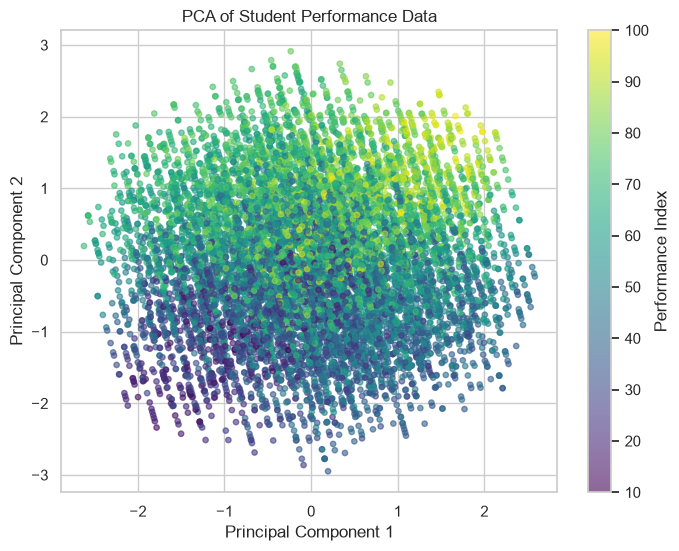

In [34]:
# Plot the two principal components
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=df1['Performance Index'], cmap='viridis', s=15, alpha=0.6
)
plt.colorbar(scatter, label='Performance Index')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of Student Performance Data')
plt.show()

In [35]:
# 9. Create performance categories for t-SNE visualization
performance_category = pd.qcut(
    df1['Performance Index'], q=3,
    labels=['Low', 'Medium', 'High'], duplicates='drop'
)
print(performance_category.value_counts())

Performance Index
Low       3407
High      3317
Medium    3276
Name: count, dtype: int64


In [36]:
# Prepare a sample for t-SNE so it runs faster
sample_size = min(2500, len(df1))
np.random.seed(42)
sample_indices = np.random.choice(len(df1), size=sample_size, replace=False)
X_tsne_data = X_pca_scaled[sample_indices]
tsne_categories = performance_category.iloc[sample_indices]
print('Students used for t-SNE:', sample_size)

Students used for t-SNE: 2500


In [37]:
# Apply t-SNE to reduce the data to two dimensions
tsne = TSNE(
    n_components=2, perplexity=30,
    init='pca', learning_rate='auto', random_state=42
)
X_tsne = tsne.fit_transform(X_tsne_data)

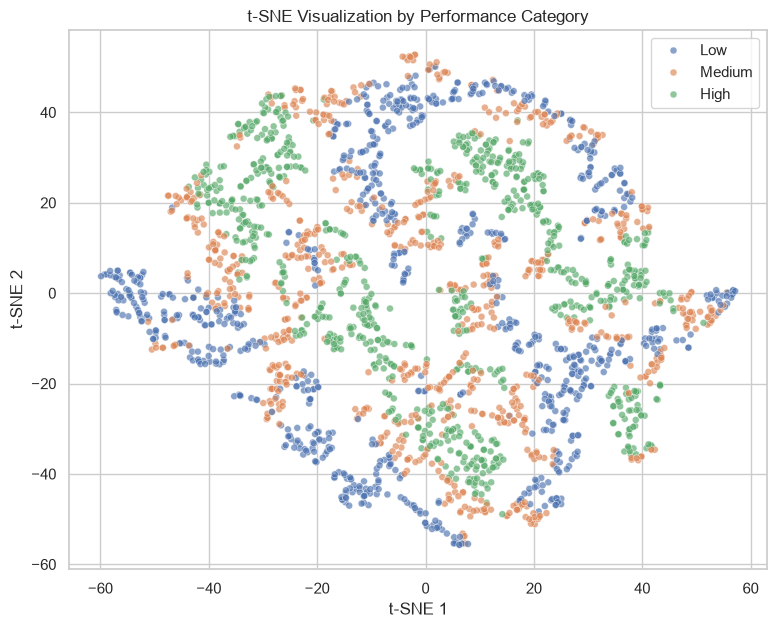

In [38]:
# Plot students by performance category
plt.figure(figsize=(9, 7))
sns.scatterplot(
    x=X_tsne[:, 0], y=X_tsne[:, 1],
    hue=tsne_categories.astype(str).to_numpy(),
    hue_order=['Low', 'Medium', 'High'],
    s=25, alpha=0.65
)
plt.title('t-SNE Visualization by Performance Category')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.show()

# t-SNE focuses on nearby points, so the axes do not have direct meanings.

In [39]:
# 10. Compare PCA and t-SNE
comparison = pd.DataFrame({
    'Aspect': ['Purpose', 'Interpretability', 'Data structure preserved', 'Typical use'],
    'PCA': [
        'Linear dimensionality reduction',
        'Components are combinations of original features',
        'Preserves directions with highest variance',
        'Variance analysis and dimensionality reduction'
    ],
    't-SNE': [
        'Nonlinear visualization',
        'Axes have no direct feature meaning',
        'Emphasizes local neighborhoods',
        'Visualizing clusters and local patterns'
    ]
})
print(comparison)

# PCA is easier to interpret; t-SNE is mainly used for visualizing local clusters.

                     Aspect                                               PCA  \
0                   Purpose                   Linear dimensionality reduction   
1          Interpretability  Components are combinations of original features   
2  Data structure preserved        Preserves directions with highest variance   
3               Typical use    Variance analysis and dimensionality reduction   

                                     t-SNE  
0                  Nonlinear visualization  
1      Axes have no direct feature meaning  
2           Emphasizes local neighborhoods  
3  Visualizing clusters and local patterns  


In [40]:
# Load the groceries dataset
# Change the filename here if your file has a different name.
df2 = pd.read_csv('Groceries_dataset.csv')
print('Groceries dataset shape:', df2.shape)
print('Column names:', df2.columns.tolist())
print(df2.head())

Groceries dataset shape: (38765, 3)
Column names: ['Member_number', 'Date', 'itemDescription']
   Member_number        Date   itemDescription
0           1808  21-07-2015    tropical fruit
1           2552  05-01-2015        whole milk
2           2300  19-09-2015         pip fruit
3           1187  12-12-2015  other vegetables
4           3037  01-02-2015        whole milk


In [41]:
# 11. Check and preprocess the groceries data
print(df2.info())
print('Missing values:')
print(df2.isnull().sum())
print('Duplicate rows:', df2.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Member_number    38765 non-null  int64
 1   Date             38765 non-null  str  
 2   itemDescription  38765 non-null  str  
dtypes: int64(1), str(2)
memory usage: 908.7 KB
None
Missing values:
Member_number      0
Date               0
itemDescription    0
dtype: int64
Duplicate rows: 759


In [42]:
# Prepare transaction IDs and clean item names
# This uses the common Groceries dataset columns: Member_number, Date, itemDescription.
df2['Date'] = pd.to_datetime(df2['Date'], errors='coerce', dayfirst=True)
df2['itemDescription'] = df2['itemDescription'].astype('string').str.strip()
df2 = df2.dropna(subset=['Member_number', 'Date', 'itemDescription'])
df2 = df2[(df2['itemDescription'] != '') & (df2['itemDescription'].str.lower() != 'nan')]
df2['Transaction'] = df2['Member_number'].astype(str) + '_' + df2['Date'].dt.strftime('%Y-%m-%d')

print(df2[['Transaction', 'itemDescription']].head())
print('Transactions:', df2['Transaction'].nunique())
print('Unique items:', df2['itemDescription'].nunique())

       Transaction   itemDescription
0  1808_2015-07-21    tropical fruit
1  2552_2015-01-05        whole milk
2  2300_2015-09-19         pip fruit
3  1187_2015-12-12  other vegetables
4  3037_2015-02-01        whole milk
Transactions: 14963
Unique items: 167


In [43]:
# Convert the transaction data into a basket matrix
basket = df2.groupby(['Transaction', 'itemDescription'])['itemDescription'].count().unstack(fill_value=0)
basket = basket > 0

print('Basket matrix shape:', basket.shape)
print(basket.head())

Basket matrix shape: (14963, 167)
itemDescription  Instant food products  UHT-milk  abrasive cleaner  \
Transaction                                                          
1000_2014-06-24                  False     False             False   
1000_2015-03-15                  False     False             False   
1000_2015-05-27                  False     False             False   
1000_2015-07-24                  False     False             False   
1000_2015-11-25                  False     False             False   

itemDescription  artif. sweetener  baby cosmetics   bags  baking powder  \
Transaction                                                               
1000_2014-06-24             False           False  False          False   
1000_2015-03-15             False           False  False          False   
1000_2015-05-27             False           False  False          False   
1000_2015-07-24             False           False  False          False   
1000_2015-11-25          

In [44]:
# 12. Apply Apriori with minimum support of 1%
frequent_itemsets = apriori(
    basket, min_support=0.01, use_colnames=True
)
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(len)

print('Number of frequent itemsets:', len(frequent_itemsets))
print(frequent_itemsets.sort_values(['length', 'support'], ascending=[True, False]).head(20))

Number of frequent itemsets: 69
     support                         itemsets  length
62  0.157923          frozenset({whole milk})       1
40  0.122101    frozenset({other vegetables})       1
46  0.110005          frozenset({rolls/buns})       1
52  0.097106                frozenset({soda})       1
63  0.085879              frozenset({yogurt})       1
47  0.069572     frozenset({root vegetables})       1
57  0.067767      frozenset({tropical fruit})       1
5   0.060683       frozenset({bottled water})       1
49  0.060349             frozenset({sausage})       1
15  0.053131        frozenset({citrus fruit})       1
41  0.051728              frozenset({pastry})       1
42  0.049054           frozenset({pip fruit})       1
50  0.047584       frozenset({shopping bags})       1
10  0.046916         frozenset({canned beer})       1
4   0.045312        frozenset({bottled beer})       1
59  0.043708  frozenset({whipped/sour cream})       1
37  0.038896          frozenset({newspapers})     

In [45]:
# 13. Generate association rules with minimum confidence of 20%
if len(frequent_itemsets) > 0:
    rules = association_rules(
        frequent_itemsets, num_itemsets=len(basket),
        metric='confidence', min_threshold=0.20
    )
    rules = rules.sort_values(['confidence', 'lift'], ascending=False).reset_index(drop=True)
else:
    rules = pd.DataFrame()

print('Number of association rules:', len(rules))
print(rules.head(20))

Number of association rules: 0
Empty DataFrame
Columns: [antecedents, consequents, antecedent support, consequent support, support, confidence, lift, representativity, leverage, conviction, zhangs_metric, jaccard, certainty, kulczynski]
Index: []


In [46]:
# 14. Display the top five rules with support, confidence and lift
if not rules.empty:
    top5_rules = rules.sort_values(['lift', 'confidence'], ascending=False).head(5).copy()
    top5_rules['Antecedents'] = top5_rules['antecedents'].apply(lambda x: ', '.join(sorted(list(x))))
    top5_rules['Consequents'] = top5_rules['consequents'].apply(lambda x: ', '.join(sorted(list(x))))

    print(top5_rules[['Antecedents', 'Consequents', 'support', 'confidence', 'lift']].round(4))
else:
    print('No rules were found with the selected thresholds.')

# Support is the proportion of all transactions containing both sides of a rule.
# Confidence is the proportion of antecedent transactions that also contain the consequent.
# Lift above 1 indicates a positive association compared with independent occurrence.

No rules were found with the selected thresholds.


In [47]:
# 15. Recommend three product combinations for cross-selling
if not rules.empty:
    recommendations = rules[rules['lift'] > 1].sort_values(
        ['lift', 'confidence', 'support'], ascending=False
    ).copy()

    recommendations['Antecedents'] = recommendations['antecedents'].apply(lambda x: ', '.join(sorted(list(x))))
    recommendations['Consequents'] = recommendations['consequents'].apply(lambda x: ', '.join(sorted(list(x))))
    recommendations = recommendations.drop_duplicates(['Antecedents', 'Consequents']).head(3)

    if len(recommendations) > 0:
        print(recommendations[['Antecedents', 'Consequents', 'support', 'confidence', 'lift']].round(4))
    else:
        print('No rules with lift greater than 1 were found.')
else:
    print('No recommendations can be made because no association rules were found.')

# These combinations can be tested as bundle offers or checkout recommendations.

No recommendations can be made because no association rules were found.
